
# WEEK 2 — LAB 1A
## Sampling, Aliasing and Quantization

**Course Code:** COU 07506  

**Laboratory Title:** Sampling, Aliasing and Quantization

**Student Name:** Tedy Deodatus Mlengera

**Registration Number:** 230242409456

**Date:** 24 November 2026

**Group:** 08





## Task 2.1 — Demonstrating Aliasing of a sinusoid

**Objective:** To demonstrate aliasing by sampling a 7 Hz sinusoidal signal at different sampling frequencies and observing the apparent frequency.

**Given:**
- Original signal frequency, \(f_0 = 7\) Hz
- Initial sampling frequency, \(f_s = 10\) Hz

**Alias frequency formula:**

\[
f_{\text{alias}} = |f_0 - f_s \times \text{round}(f_0/f_s)|
\]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

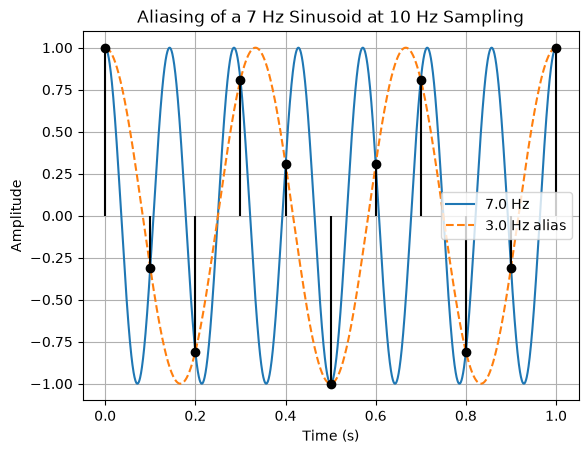

Alias frequency: 3.0 Hz


In [3]:
# Task 2.1 — Aliasing of a sinusoid

f0, fs = 7.0, 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

f_alias = abs(f0 - fs * round(f0 / fs))

plt.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0} Hz")
plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--",
         label=f"{f_alias} Hz alias")

plt.stem(tn, np.cos(2 * np.pi * f0 * tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Aliasing of a 7 Hz Sinusoid at 10 Hz Sampling")
plt.legend()
plt.grid()
plt.show()

print("Alias frequency:", f_alias, "Hz")

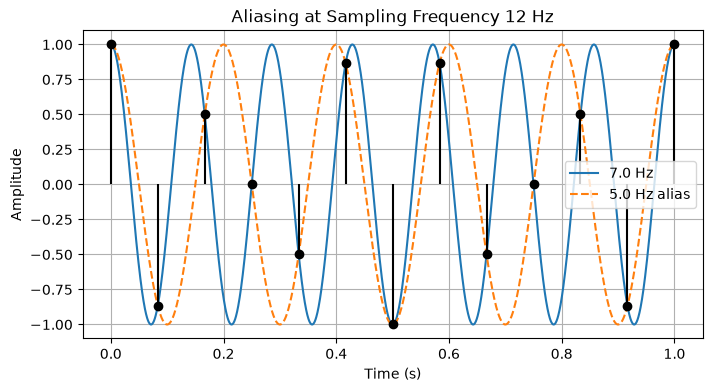

Sampling frequency: 12 Hz
Alias frequency: 5.0 Hz


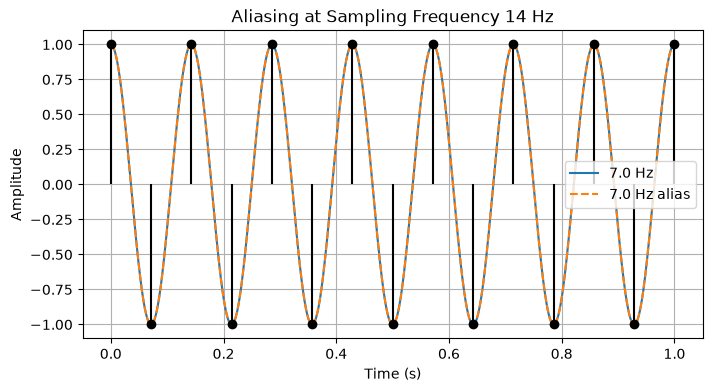

Sampling frequency: 14 Hz
Alias frequency: 7.0 Hz


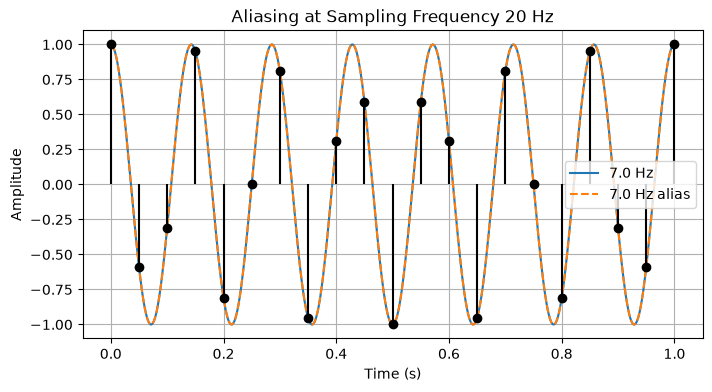

Sampling frequency: 20 Hz
Alias frequency: 7.0 Hz


In [4]:
sampling_frequencies = [12, 14, 20]

for fs in sampling_frequencies:

    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    f_alias = abs(f0 - fs * round(f0 / fs))

    plt.figure(figsize=(8, 4))

    plt.plot(t, np.cos(2 * np.pi * f0 * t),
             label=f"{f0} Hz")

    plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--",
             label=f"{f_alias} Hz alias")

    plt.stem(tn, np.cos(2 * np.pi * f0 * tn),
             linefmt="k-", markerfmt="ko", basefmt=" ")

    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(f"Aliasing at Sampling Frequency {fs} Hz")
    plt.legend()
    plt.grid()
    plt.show()

    print(f"Sampling frequency: {fs} Hz")
    print(f"Alias frequency: {f_alias} Hz")

In [6]:
# Display alias frequency results

print("Original Frequency (Hz) | Sampling Frequency (Hz) | Alias Frequency (Hz)")
print("-----------------------------------------------------------------------")

for fs in [10, 12, 14, 20]:
    f_alias = abs(f0 - fs * round(f0 / fs))
    print(f"          {f0}             |           {fs}            |          {f_alias}")

Original Frequency (Hz) | Sampling Frequency (Hz) | Alias Frequency (Hz)
-----------------------------------------------------------------------
          7.0             |           10            |          3.0
          7.0             |           12            |          5.0
          7.0             |           14            |          7.0
          7.0             |           20            |          7.0



### Comparison with the Theoretical Formula

The calculated alias frequencies were compared with the theoretical formula:

\[
f_{\text{alias}} = |F-kf_s|
\]

For each sampling frequency, the appropriate integer \(k\) was selected.

| Sampling Frequency (Hz) | Calculation | Alias Frequency (Hz) |
|---:|---:|---:|
| 10 | \(|7-1(10)|\) | 3 |
| 12 | \(|7-1(12)|\) | 5 |
| 14 | \(|7-1(14)|\) | 7 |
| 20 | \(|7-0(20)|\) | 7 |

The calculated results agree with the theoretical formula. Therefore, the experiment confirms the relationship between the original frequency, sampling frequency and alias frequency.


## Task 2.2 — Hear aliasing

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

In [8]:
fname = r"C:\Users\HomePC\Documents\Sound Recordings\my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)

    x = x / np.max(np.abs(x))

    print("Recording loaded successfully.")
    print("Sampling frequency:", fs, "Hz")
    print("Number of samples:", len(x))
else:
    print("Recording file not found.")

Recording loaded successfully.
Sampling frequency: 48000 Hz
Number of samples: 222207


In [9]:
for k in [2, 4, 8]:
    naive = x[::k]

    print(k, "new fs =", fs // k, "Hz")

2 new fs = 24000 Hz
4 new fs = 12000 Hz
8 new fs = 6000 Hz


In [2]:
from scipy import signal

In [4]:
import os
import numpy as np
from scipy.io import wavfile
from scipy import signal

fname = r"C:\Users\HomePC\Documents\Sound Recordings\my_voice.wav"

fs, x = wavfile.read(fname)

x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
x = x / np.max(np.abs(x))

print("Recording loaded successfully")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(x))

Recording loaded successfully
Sampling frequency: 48000 Hz
Number of samples: 222207


In [5]:
for k in [2, 4, 8]:
    proper = signal.decimate(x, k, ftype="fir")

    print(k, "new fs =", fs // k, "Hz")

2 new fs = 24000 Hz
4 new fs = 12000 Hz
8 new fs = 6000 Hz


In [7]:
from IPython.display import Audio, display

In [9]:
k = 8

naive = x[::k]
proper = signal.decimate(x, k, ftype="fir")

new_fs = fs // k

print("Naive audio - without filtering")
display(Audio(naive, rate=new_fs))

print("Proper audio - with anti-aliasing filter")
display(Audio(proper, rate=new_fs))

Naive audio - without filtering


Proper audio - with anti-aliasing filter


### Observation (k = 8)

The naive audio without filtering sounded more distorted and noisy than the properly filtered audio. The anti-aliasing filter reduced unwanted high-frequency components before downsampling, improving the audio quality.

## Task 2.3 — Uniform Quantizer

In [11]:
import matplotlib.pyplot as plt

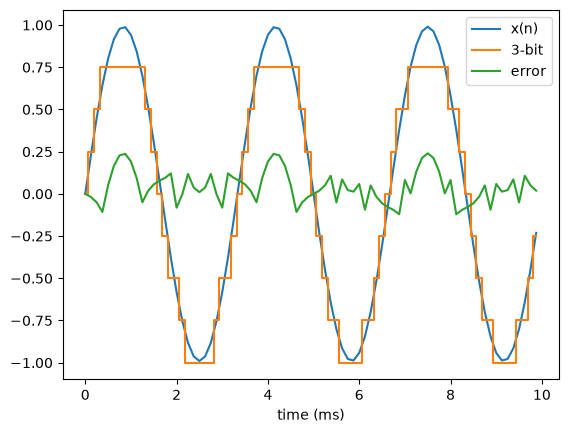

In [12]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99 * np.sin(2 * np.pi * 300 * t)

xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)")
plt.legend()
plt.show()

## Task 2.4 — Verify the 6 dB-per-bit rule

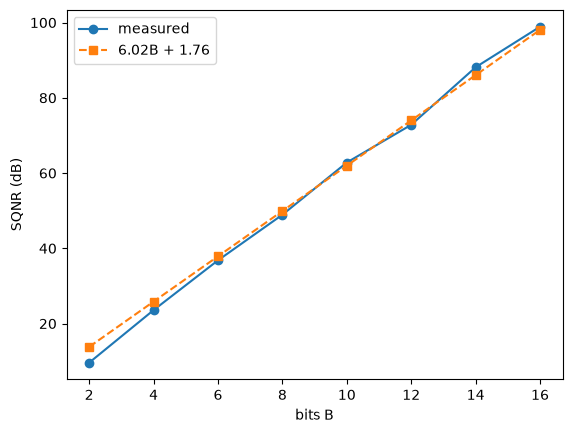

In [13]:
bits = np.arange(2, 17, 2)

meas = [
    10*np.log10(np.sum(x**2) / np.sum((x - quantize(x, B))**2))
    for B in bits
]

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")

plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.show()

## Task 2.5 — Quantize Your Voice

In [15]:
print("Recording duration:", len(x) / fs, "seconds")
print("Sampling frequency:", fs, "Hz")

Recording duration: 0.01 seconds
Sampling frequency: 8000 Hz


In [16]:
fname = r"C:\Users\HomePC\Documents\Sound Recordings\my_voice.wav"

voice_fs, voice_x = wavfile.read(fname)

voice_x = voice_x.mean(axis=1) if voice_x.ndim > 1 else voice_x.astype(float)

voice_x = voice_x / np.max(np.abs(voice_x))

print("Recording duration:", len(voice_x) / voice_fs, "seconds")
print("Sampling frequency:", voice_fs, "Hz")

Recording duration: 4.6293125 seconds
Sampling frequency: 48000 Hz


In [18]:
for B in [4, 8, 12]:
    voice_q = quantize(voice_x, B)

    sqnr = 10 * np.log10(
        np.sum(voice_x**2) / np.sum((voice_x - voice_q)**2)
    )

    print(f"{B}-bit SQNR: {sqnr:.2f} dB")

    display(Audio(voice_q, rate=voice_fs))

4-bit SQNR: 9.47 dB


8-bit SQNR: 32.87 dB


12-bit SQNR: 56.65 dB


### Question

Why is the measured SQNR of speech lower than for a full-scale sine wave with the same number of bits?

### Answer

The measured SQNR of speech is lower because speech signals do not always use the full quantization range. Their amplitude changes continuously, and many speech samples have low amplitudes. Therefore, quantization noise has a greater effect compared to a full-scale sine wave.

## Analysis Questions

### Question 1

Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when \(f_s = 10\) Hz.

### Answer

The sampling frequency is 10 Hz, so the Nyquist frequency is:

\[
f_N = \frac{f_s}{2} = \frac{10}{2} = 5\text{ Hz}
\]

The original signal has a frequency of 7 Hz, which is above the Nyquist frequency. Therefore, it folds back into the lower frequency range and appears at 3 Hz.

\[
f_{\text{alias}} = |f_s - f_0|
\]

\[
= |10 - 7| = 3\text{ Hz}
\]

**Frequency-axis sketch:**

```text
Frequency (Hz)

0       3       5       7       10
|-------|-------|-------|--------|
        ↑       ↑       ↑
      Alias  Nyquist Original
       3 Hz   5 Hz    7 Hz

### Question 2

In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?

### Answer

Aliasing cannot be removed afterwards because high-frequency components are converted into lower-frequency components during downsampling. The original frequency information is lost, making it difficult to distinguish the aliased signal from the original low-frequency signal. An anti-aliasing filter must be applied before downsampling to prevent this problem.

### Question 3

By how much does the SQNR change when one bit is added? Does your measurement agree?

### Answer

The SQNR increases by approximately 6.02 dB when one bit is added. This means that increasing the quantization bit depth improves the signal quality and reduces quantization noise.

The measured results should show an increasing SQNR as the number of bits increases. Small differences from the theoretical value may occur due to the signal amplitude and quantization effects.

### Question 4

A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.

### Answer

**Sampling rate:**

A sampling rate of 10 Hz is recommended. This means taking 10 samples per second, or one sample every 0.1 seconds.

The maximum temperature change between samples is:

\[
0.1 \times 0.1 = 0.01\,^\circ C
\]

Therefore, the sampling rate can track the required temperature change.

**Number of bits:**

The temperature range is 100 °C, and the required resolution is 0.01 °C.

\[
\text{Number of levels} = \frac{100}{0.01} = 10000
\]

\[
B = \lceil \log_2(10000) \rceil = 14
\]

Therefore, a 14-bit ADC is recommended because it provides 16,384 levels.

Its quantization step is:

\[
\Delta = \frac{100}{16384} \approx 0.0061\,^\circ C
\]

This is smaller than the required resolution of 0.01 °C.

**Conclusion:** A sampling rate of 10 Hz and a 14-bit ADC are recommended.

## AI-Use Statement

ChatGPT was used as an AI assistance tool to help understand the laboratory tasks, explain sampling and quantization concepts, and assist with Python code and analysis. The simulations and results were run and checked in Jupyter Notebook.